# Engression models vs. probabilistic Darts baselines: Venezuela dengue and malaria, H = 4 and 13 weeks

This notebook produces the experimental results for the book chapter. For each dataset (Venezuela dengue, Venezuela malaria), each forecast horizon (short H = 4, long H = 13 weeks) and each of seven architectures, it compares the **engression** model from `engressionts` with its **probabilistic Darts counterpart**:

| Architecture | Engression model | Darts baseline |
|---|---|---|
| LSTM (block RNN) | EnBlockRNN | `BlockRNNModel` (LSTM) |
| Temporal convolution | EnTCN | `TCNModel` |
| Transformer | EnTransformer | `TransformerModel` |
| TSMixer | EnTSMixer | `TSMixerModel` |
| N-BEATS (generic) | EnBEATS | `NBEATSModel` |
| N-HiTS | EnHiTS | `NHiTSModel` |
| TiDE | EnTiDE | `TiDEModel` |

**Baselines.** Each Darts baseline copies the *tuned* settings of its engression counterpart (architecture, learning rate, log transform) and differs only in how it produces a distribution: a **Gaussian likelihood** (mean and variance per step, trained by negative log-likelihood and sampled at forecast time) instead of engression's noise-driven generator trained with the energy score. The comparison therefore isolates the effect of engression. The baselines were not tuned separately.

**Inputs.** The tuning studies (`.db` files) of the 28 tuning runs (7 models × 2 datasets × 2 horizons), from the `*-tune.ipynb` notebooks. The notebook finds them under `/kaggle/input` and tells the datasets apart from the settings stored with each study.

**Protocol** (identical for every model and both datasets). The log transform (if selected) and standardisation are fitted on train + validation. Each model is retrained on train + validation with **5 training seeds** and forecasts the test window once from its last week. Each trained model then draws **50 ensembles of 100 trajectories**. Metrics are computed per ensemble and averaged. The test window is used only here.

| Part | Contents |
|---|---|
| 0–1 | Installation, imports, configuration (**`RUN_MODELS`**) |
| 2 | Forecast heads (EnBlockRNN and EnTCN fix) and the Gaussian baselines |
| 3 | Data, splits and leakage checks |
| 4 | Collect the tuned settings from the tuning studies |
| 5 | Model builders |
| 6 | Train and forecast (results are saved per model, so the work can be split over several sessions) |
| 7 | Table 1 (dengue) and Table 2 (malaria) |
| 8 | Figure 1 (forecasts) and Figure 2 (CRPS and coverage, engression vs. baseline) |
| 9 | Supplementary tables, a fact sheet for the write-up, and saving everything |

**Kaggle workflow** (Kaggle stops a run after 12 hours):
1. **Add Input**: all tuning notebooks whose `.db` files hold the 28 studies (dengue and malaria). Turn **Internet On**.
2. **Session A (GPU):** set `RUN_MODELS = ["entransformer", "enbeats"]` and Save & Run All.
3. **Session B (CPU):** set `RUN_MODELS = ["enblockrnn", "entcn", "entsmixer", "enhits", "entide"]` and Save & Run All. If it gets close to 12 hours, split it into two sessions.
4. **Final session:** **Add Input** the outputs of sessions A and B as well, set `RUN_MODELS = []` and Save & Run All. It trains nothing; it loads all saved results and builds the tables and figures. Any session already builds them from whatever results exist so far.

## Part 0 — Installation and imports

Same versions as the tuning notebooks: `darts` **0.47.0** (0.48 breaks `engressionts 0.1.1`), `engressionts` 0.1.1, `pytorch-lightning`, `optuna`, `openpyxl`.

In [1]:
%%capture install_log
!pip install -q "darts==0.47.0" "engressionts==0.1.1" pytorch-lightning openpyxl optuna

In [2]:
import os, sys, json, time, glob, shutil, platform, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import torch, optuna
import torch.nn as nn
from optuna.trial import TrialState

import darts, pytorch_lightning as pl
from darts import TimeSeries
from darts.dataprocessing import Pipeline
from darts.dataprocessing.transformers import Scaler, InvertibleMapper
from darts.models import (BlockRNNModel, TCNModel, TransformerModel, TSMixerModel, NBEATSModel, NHiTSModel, TiDEModel)
from darts.models.forecasting.block_rnn_model import CustomBlockRNNModule as DartsCustomBlockRNNModule
from darts.models.forecasting.tcn_model import _TCNModule as DartsTCNModule
from darts.models.forecasting.pl_forecasting_module import io_processor
from darts.models.forecasting.torch_forecasting_model import PastCovariatesTorchModel
from darts.utils.likelihood_models import GaussianLikelihood
from sklearn.preprocessing import StandardScaler

import engressionts
import engressionts.base.base_engression as eng_base
from engressionts.models import (EnBlockRNNModel, EnTCNModel, EnTransformerModel, EnTSMixerModel,
                                 EnBEATSModel, EnHiTSModel, EnTiDEModel)
from engressionts.models.enblock_rnn_model import CustomBlockRNNModule as EnCustomBlockRNNModule
from engressionts.models.entcn_model import _EnTCNModule as EnTCNModule
from engressionts import metrics as M

warnings.filterwarnings("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "darts"]:
    logging.getLogger(name).setLevel(logging.ERROR)
optuna.logging.set_verbosity(optuna.logging.WARNING)

VERSIONS = {"python": platform.python_version(), "engressionts": engressionts.__version__, "darts": darts.__version__,
            "pytorch_lightning": pl.__version__, "torch": torch.__version__, "optuna": optuna.__version__,
            "numpy": np.__version__, "pandas": pd.__version__}
print(json.dumps(VERSIONS, indent=2))
assert darts.__version__.startswith("0.4") and not darts.__version__.startswith("0.48"), \
    "darts 0.48+ breaks engressionts 0.1.1 — rerun Part 0 and restart the kernel"
ACCELERATOR = "gpu" if torch.cuda.is_available() else "cpu"
print("Accelerator:", ACCELERATOR, "|", torch.cuda.get_device_name(0) if ACCELERATOR == "gpu" else "")

{
  "python": "3.13.16",
  "engressionts": "0.1.1",
  "darts": "0.47.0",
  "pytorch_lightning": "2.6.6",
  "torch": "2.11.0+cu130",
  "optuna": "5.1.0",
  "numpy": "2.1.3",
  "pandas": "2.3.3"
}
Accelerator: gpu | Tesla T4


## Part 1 — Configuration

**`RUN_MODELS`** chooses which models this session trains (for both datasets in `RUN_DATASETS`). Models already trained, in this session or in an earlier one attached as input, are loaded instead of retrained. Leave everything else as it is: it matches the tuning notebooks (lookback 52, M = 2, 100 epochs, batch 32, splits) and the final protocol (5 seeds × 50 ensembles × 100 trajectories, 95% intervals).

In [3]:
RUN_MODELS = "all"                  # "all" | a list, e.g. ["entransformer", "enbeats"] | [] (only build tables and figures)
RUN_DATASETS = ["dengue", "malaria"]
RUN_MODE = "full"                   # "full" | "quick" (smoke test: 5 epochs, 2 seeds, 3 ensembles, tuning not required to be complete)

DENGUE_URL = "https://raw.githubusercontent.com/mad-stat/Epicasting/main/Datasets/Dengue_datasets/Venezuela_Dengue.xlsx"
MALARIA_URL = "https://raw.githubusercontent.com/mad-stat/Epicasting/main/Datasets/Malaria_datasets/Venezuela_Malaria.xlsx"
CFG = dict(
    DATASETS={"dengue": dict(url=DENGUE_URL, local="/kaggle/input/epicasting/Venezuela_Dengue.xlsx", label="Venezuela dengue"),
              "malaria": dict(url=MALARIA_URL, local="/kaggle/input/epicasting/Venezuela_Malaria.xlsx", label="Venezuela malaria")},
    FREQ="W-MON",
    HORIZONS={"short": {"H": 4, "V": 9}, "long": {"H": 13, "V": 26}},
    LOOKBACK=52,              # input_chunk_length p (as in tuning)
    M_TRAIN=2,                # engression: noisy copies per window in the energy score (as in tuning)
    N_EPOCHS=100,
    BATCH_SIZE=32,
    N_TRIALS=100,             # a study counts as complete with this many finished trials
    N_PRED_SAMPLES=100,       # S: trajectories per ensemble
    N_EVAL_REPEATS=50,        # ensembles per trained model
    SEEDS=[0, 1, 2, 3, 4],    # training seeds (the same for every model)
    ALPHA=0.05,               # 95% prediction intervals
    BASELINE_LIKELIHOOD="gaussian",
    PLOT_HISTORY=20,          # weeks of history shown before each forecast in Figure 1
    PLOT_YMAX_FACTOR=1.6,     # Figure 1 y-axis top = this x the largest observed value in the row (intervals beyond are cut off)
    OUT_DIR="outputs_results",
    TUNING_INPUTS=["/kaggle/input", "."],   # searched (recursively) for the tuning studies' .db files
    RESULT_INPUTS=["/kaggle/input"],        # searched for results saved by earlier sessions of this notebook
    REQUIRE_FULL_TUNING=True,
)
# Studies accepted as they are, although they fail one of the checks below (stated in the write-up):
# malaria EnBEATS was tuned with the earlier EnBEATS notebook (num_layers 1-5, layer_widths 8-256 instead of the
# shared 1-4 and 16-256), and its short-horizon run stopped at 96 of 100 trials (Kaggle's 12-hour limit).
ACCEPT_AS_IS = {("malaria", "enbeats"): dict(skip_space_check=True, min_trials=96)}
if RUN_MODE == "quick":
    CFG.update(N_EPOCHS=5, SEEDS=[0, 1], N_EVAL_REPEATS=3, REQUIRE_FULL_TUNING=False, OUT_DIR="outputs_results_quick")
os.makedirs(CFG["OUT_DIR"], exist_ok=True)

# Models in table order: engression name, Darts baseline name
MODELS = {"enblockrnn": ("EnBlockRNN", "BlockRNN"), "entcn": ("EnTCN", "TCN"),
          "entransformer": ("EnTransformer", "Transformer"), "entsmixer": ("EnTSMixer", "TSMixer"),
          "enbeats": ("EnBEATS", "N-BEATS"), "enhits": ("EnHiTS", "N-HiTS"), "entide": ("EnTiDE", "TiDE")}
RUN_MODELS = list(MODELS) if RUN_MODELS == "all" else list(RUN_MODELS)
assert set(RUN_MODELS) <= set(MODELS) and set(RUN_DATASETS) <= set(CFG["DATASETS"]), (RUN_MODELS, RUN_DATASETS)
KINDS = ("engression", "baseline")
METRICS = ["MAE", "RMSE", "CRPS", "Coverage95", "Width95"]            # reported in Tables 1-2
EXTRA_METRICS = ["MASE", "Winkler95", "Pinball80", "Pinball95"]         # saved, not tabulated
print("This session trains:", RUN_MODELS, "on", RUN_DATASETS, "|", RUN_MODE)

This session trains: ['enblockrnn', 'entcn', 'entransformer', 'entsmixer', 'enbeats', 'enhits', 'entide'] on ['dengue', 'malaria'] | full


## Part 2 — Forecast heads and the Gaussian baselines

**EnBlockRNN and EnTCN** were tuned with a fixed forecast head (see their tuning notebooks): the package heads map the network output at input week p − H + k to forecast step k, so step 1 ignores the last H − 1 weeks. The fixed heads read all H steps from the network state after the **whole** input window: `h_n[-1]` of the LSTM, or the last time position of the TCN. The same heads are used here, as recorded in each study's settings (`HEAD`), and the **Darts BlockRNN and TCN baselines get the same heads**, so each pair differs only in engression vs. likelihood. The other five architectures use the package models as shipped; every forecast step already sees the whole window.

**Gaussian baselines.** `likelihood=GaussianLikelihood()` makes each Darts network output a mean and a standard deviation per forecast step on the transformed scale (log1p if selected, then standardised). It is trained by Gaussian negative log-likelihood; at forecast time Darts draws samples from these Gaussians. The samples are independent across forecast steps, unlike engression trajectories, which are drawn jointly. That makes no difference to the per-step metrics reported here.

In [4]:
def _fc_head(module):
    # Linear layer(s): final hidden state (hidden_dim) -> all H steps (H * C * nr_params)
    feats, last = [], module.hidden_dim
    sizes = module.num_layers_out_fc + [module.output_chunk_length * module.target_size * module.nr_params]
    for i, f in enumerate(sizes):
        feats.append(nn.Linear(last, f))
        if i < len(module.num_layers_out_fc):
            feats.append(nn.ReLU())
        last = f
    return nn.Sequential(*feats)


class LastStateEnLSTM(EnCustomBlockRNNModule):
    # EnBlockRNN fixed head: noise on the input window -> LSTM -> h_n[-1] -> linear -> H steps
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.rnn = nn.LSTM(self.input_size, self.hidden_dim, self.num_layers, batch_first=True, dropout=self.dropout)
        self.fc = _fc_head(self)

    @io_processor
    def forward(self, x_in):
        x_past = self.noise_layer(x_in[0])
        _, (h_n, _) = self.rnn(x_past)
        out = self.fc(h_n[-1])
        return out.view(x_past.shape[0], self.output_chunk_length, self.target_size, self.nr_params)


class LastStateLSTM(DartsCustomBlockRNNModule):
    # Same head without noise, for the Darts BlockRNN baseline (nr_params = 2 with the Gaussian likelihood)
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.rnn = nn.LSTM(self.input_size, self.hidden_dim, self.num_layers, batch_first=True, dropout=self.dropout)
        self.fc = _fc_head(self)

    @io_processor
    def forward(self, x_in):
        x_past = x_in[0]
        _, (h_n, _) = self.rnn(x_past)
        out = self.fc(h_n[-1])
        return out.view(x_past.shape[0], self.output_chunk_length, self.target_size, self.nr_params)


def _last_step_output(module, x):
    # x (B, p, C) -> TCN stack (B, H * C * nr_params, p) -> keep the LAST time position -> (B, H, C, nr_params)
    x = x.transpose(1, 2)
    for block in module.res_blocks_list:
        x = block(x)
    return x[:, :, -1].reshape(x.shape[0], module.output_chunk_length, module.n_targets, module.nr_params)


class LastStepEnTCN(EnTCNModule):
    def __init__(self, target_size, **kwargs):
        super().__init__(target_size=target_size * kwargs["output_chunk_length"], **kwargs)
        self.n_targets = target_size

    @io_processor
    def forward(self, x_in):
        return _last_step_output(self, self.noise_layer(x_in[0]))

    @property
    def first_prediction_index(self):
        return 0


class LastStepTCN(DartsTCNModule):
    def __init__(self, target_size, **kwargs):
        super().__init__(target_size=target_size * kwargs["output_chunk_length"], **kwargs)
        self.n_targets = target_size

    @io_processor
    def forward(self, x_in):
        return _last_step_output(self, x_in[0])

    @property
    def first_prediction_index(self):
        return 0


class _LastStepModel:
    # Builds the fixed-head TCN module (with as many output parameters as the likelihood needs)
    # and trains on ordinary windows (p weeks in -> the next H weeks out)
    _module_class = None

    def _create_model(self, train_sample):
        past_target, past_cov = train_sample[0], train_sample[1]
        lik = getattr(self, "likelihood", None)
        noise = (dict(noise_std=self.noise_std, noise_type=self.noise_type, num_samples=self.num_samples)
                 if isinstance(self, EnTCNModel) else {})
        return self._module_class(
            input_size=past_target.shape[1] + (past_cov.shape[1] if past_cov is not None else 0),
            target_size=past_target.shape[1], nr_params=1 if lik is None else lik.num_parameters,
            kernel_size=self.kernel_size, num_filters=self.num_filters, num_layers=self.num_layers,
            dilation_base=self.dilation_base, target_length=self.output_chunk_length, dropout=self.dropout,
            weight_norm=self.weight_norm, **noise, **dict(self.pl_module_params or {}))

    def _build_train_dataset(self, *args, **kwargs):
        return PastCovariatesTorchModel._build_train_dataset(self, *args, **kwargs)


class LastStepEnTCNModel(_LastStepModel, EnTCNModel):
    _module_class = LastStepEnTCN


class LastStepTCNModel(_LastStepModel, TCNModel):
    _module_class = LastStepTCN


def make_scaler(log_transform):
    # Unfitted transform: [log1p] -> standardise
    steps = [InvertibleMapper(np.log1p, np.expm1, name="log1p")] if log_transform else []
    return Pipeline(steps + [Scaler(StandardScaler())])

def baseline_likelihood():
    assert CFG["BASELINE_LIKELIHOOD"] == "gaussian"
    return GaussianLikelihood()
print("Heads and baselines defined | baseline likelihood:", CFG["BASELINE_LIKELIHOOD"])

Heads and baselines defined | baseline likelihood: gaussian


## Part 3 — Data, splits and leakage checks

Both files have the columns `Year`, `Week`, `Cases`, with weeks labelled 1–52 every year. As in the tuning notebooks, the rows are consecutive weeks, so a consecutive weekly index is built from the first row. For each horizon: **test** = the last H weeks, **validation** = the V weeks before it (used only by the tuning runs), **train** = everything before that. Models here are fitted on **train + validation**.

dengue: 660 weeks from https://raw.githubusercontent.com/mad-stat/Epicasting/main/Datasets/Dengue_datasets/Venezuela_Dengue.xlsx
malaria: 669 weeks from https://raw.githubusercontent.com/mad-stat/Epicasting/main/Datasets/Malaria_datasets/Venezuela_Malaria.xlsx


H   V  weeks  train + validation weeks  \
dataset horizon                                            
dengue  short     4   9    660                       656   
        long     13  26    660                       647   
malaria short     4   9    669                       665   
        long     13  26    669                       656   

                      train + validation                     test  \
dataset horizon                                                     
dengue  short    2001-12-31 → 2014-07-21  2014-07-28 → 2014-08-18   
        long     2001-12-31 → 2014-05-19  2014-05-26 → 2014-08-18   
malaria short    2001-12-31 → 2014-09-22  2014-09-29 → 2014-10-20   
        long     2001-12-31 → 2014-07-21  2014-07-28 → 2014-10-20   

                 test mean / validation mean  
dataset horizon                               
dengue  short                           1.63  
        long                            1.09  
malaria short                           1.01  
        long                            1.11

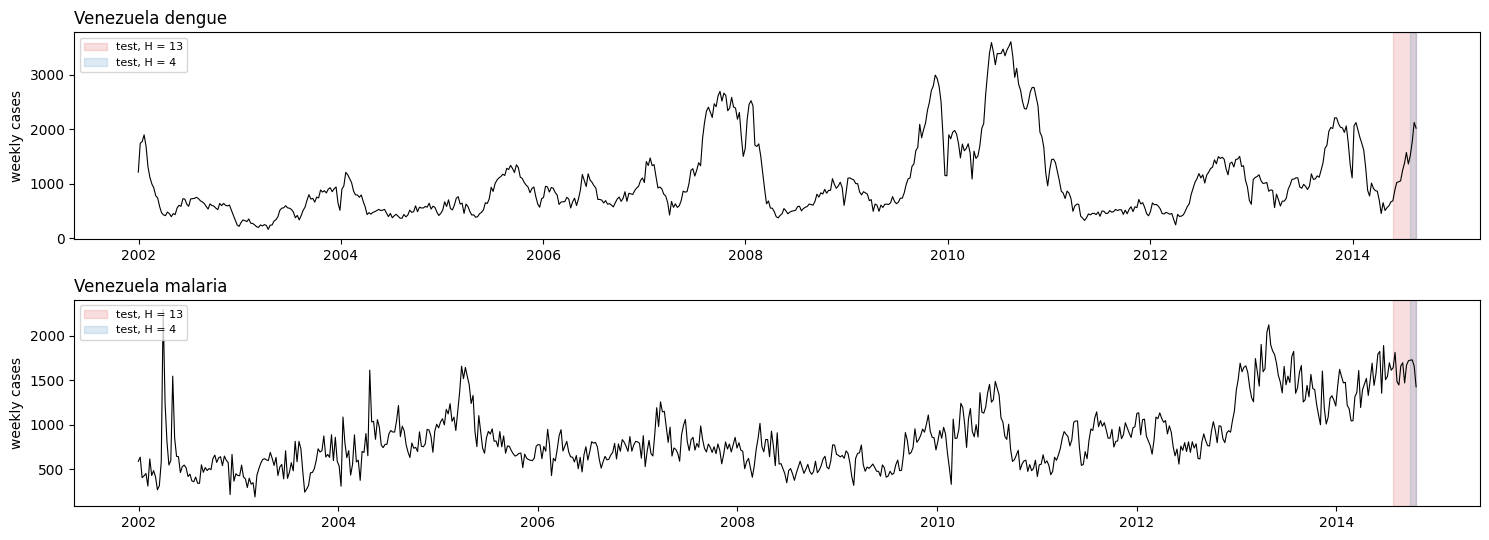

In [5]:
def load_series(ds):
    d = CFG["DATASETS"][ds]
    src = d["local"] if os.path.exists(d["local"]) else d["url"]
    raw = pd.read_excel(src)
    checks = {"columns are Year/Week/Cases": list(raw.columns) == ["Year", "Week", "Cases"],
              "no missing values": raw.isna().sum().sum() == 0,
              "no duplicate (Year, Week)": not raw.duplicated(["Year", "Week"]).any(),
              "rows in time order": raw[["Year", "Week"]].apply(tuple, axis=1).is_monotonic_increasing,
              "non-negative cases": (raw["Cases"] >= 0).all()}
    assert all(checks.values()), (ds, checks)
    start = pd.to_datetime(f"{raw.Year.iloc[0]}-W{raw.Week.iloc[0]:02d}-1", format="%G-W%V-%u")
    df = raw.assign(date=pd.date_range(start, periods=len(raw), freq=CFG["FREQ"]))
    return TimeSeries.from_dataframe(df, time_col="date", value_cols="Cases", freq=CFG["FREQ"]).astype(np.float32), src

P = CFG["LOOKBACK"]
SERIES, SPLITS, rows = {}, {}, []
for ds in CFG["DATASETS"]:
    s, src = load_series(ds); SERIES[ds] = s; SPLITS[ds] = {}
    for h, hv in CFG["HORIZONS"].items():
        H, V = hv["H"], hv["V"]; n_train = len(s) - H - V
        sp = dict(H=H, V=V, n_train=n_train, train=s[:n_train], val=s[n_train:n_train + V],
                  train_val=s[:n_train + V], test=s[-H:])
        # leakage checks: the test window is disjoint from, and strictly after, everything used for fitting
        assert len(sp["train_val"]) == len(s) - H and sp["train_val"].end_time() < sp["test"].start_time()
        assert sp["train"].end_time() < sp["val"].start_time() <= sp["val"].end_time() < sp["test"].start_time()
        SPLITS[ds][h] = sp
        rows.append({"dataset": ds, "horizon": h, "H": H, "V": V, "weeks": len(s), "train + validation weeks": n_train + V,
                     "train + validation": f"{s.start_time().date()} → {sp['train_val'].end_time().date()}",
                     "test": f"{sp['test'].start_time().date()} → {sp['test'].end_time().date()}",
                     "test mean / validation mean": round(float(sp["test"].values().mean() / sp["val"].values().mean()), 2)})
    print(f"{ds}: {len(s)} weeks from {src}")
split_table = pd.DataFrame(rows).set_index(["dataset", "horizon"])
display(split_table)

fig, axes = plt.subplots(2, 1, figsize=(15, 5.5))
for ax, ds in zip(axes, CFG["DATASETS"]):
    s = SERIES[ds]; ax.plot(s.time_index, s.values().ravel(), color="black", lw=0.8)
    for h, col in [("long", "tab:red"), ("short", "tab:blue")]:
        t = SPLITS[ds][h]["test"]; ax.axvspan(t.start_time(), t.end_time(), color=col, alpha=0.15, label=f"test, H = {SPLITS[ds][h]['H']}")
    ax.set_title(CFG["DATASETS"][ds]["label"], loc="left"); ax.set_ylabel("weekly cases"); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/figS1_series.png", dpi=150); plt.show()

## Part 4 — Tuned settings from the tuning studies

Every `.db` file under `TUNING_INPUTS` is opened read-only (a copy) and each study `<model>_<horizon>_H<H>` is listed. **The dataset is read from the settings stored with the study:** malaria studies record the malaria data URL, and dengue studies record no URL (the dengue notebooks predate that field). For each (dataset, model, horizon) the notebook keeps the matching study with the most finished trials.

Checks: lookback, M, epochs, batch size, loss and the horizon's H and V must match this notebook. In full mode the study must have been run in full mode with at least `N_TRIALS` finished trials. For EnHiTS, EnBEATS and EnTiDE the search space must be the one from the shared dengue notebooks (repository *SURVEY-ON-ENGRESSION-*), so that both datasets use the same space.

**Exception (`ACCEPT_AS_IS` in Part 1):** malaria EnBEATS was tuned with an earlier EnBEATS notebook whose space was slightly wider (`num_layers` 1–5 and `layer_widths` 8–256, instead of 1–4 and 16–256), and its short-horizon run stopped at 96 of 100 trials at Kaggle's 12-hour limit. Both studies are accepted as they are, all other checks still apply, and the `note` column records the difference. Mention it in the write-up.

The best trial's settings (`BEST`) are then used unchanged for the engression model, and its architecture, learning rate and log transform for the baseline.

In [6]:
EXPECTED_SPACE = {"enhits": {"num_layers": [1, 3], "layer_widths": [16, 512]},      # partner's search spaces
                  "enbeats": {"num_layers": [1, 4], "layer_widths": [16, 256]},
                  "entide": {"hidden_size": [16, 512], "temporal_decoder_hidden": [8, 128]}}

def n_finished(st):
    return sum(t.state in (TrialState.COMPLETE, TrialState.PRUNED) for t in st.trials)

def dataset_of(fp):
    url = (fp or {}).get("DATA_URL") or DENGUE_URL                  # dengue studies store no URL
    return next((ds for ds, d in CFG["DATASETS"].items() if d["url"] == url), None)

def check_fp(key, h, fp, ds=None):
    # Returns a list of problems (empty = fine). fp None = an older study without stored settings.
    if fp is None:
        return []
    exc = ACCEPT_AS_IS.get((ds, key), {})
    hv, out = CFG["HORIZONS"][h], []
    want = dict(LOOKBACK=CFG["LOOKBACK"], M_TRAIN=CFG["M_TRAIN"], BATCH_SIZE=CFG["BATCH_SIZE"], ES_LOSS="package",
                H=hv["H"], V=hv["V"])
    if RUN_MODE == "full":
        want.update(N_EPOCHS=CFG["N_EPOCHS"], run_mode="full")
    out += [f"{k}={fp.get(k)!r} (expected {v!r})" for k, v in want.items() if fp.get(k) != v]
    for p, rng in ({} if exc.get("skip_space_check") else EXPECTED_SPACE.get(key, {})).items():
        if list(fp.get("search_space", {}).get(p, [])) != rng:
            out.append(f"search space {p}={fp.get('search_space', {}).get(p)} (expected {rng})")
    return out

staging = os.path.join(CFG["OUT_DIR"], "_staging"); shutil.rmtree(staging, ignore_errors=True); os.makedirs(staging)
db_files = sorted({os.path.abspath(p) for root in CFG["TUNING_INPUTS"] if os.path.isdir(root)
                   for p in glob.glob(os.path.join(root, "**", "*.db"), recursive=True)
                   if not os.path.abspath(p).startswith(os.path.abspath(CFG["OUT_DIR"]))})
print(f"Found {len(db_files)} .db file(s)")
CANDS = {}                                          # (dataset, model, horizon) -> list of candidate studies
for i, path in enumerate(db_files):
    local = os.path.join(staging, f"{i}.db"); shutil.copy(path, local); url = f"sqlite:///{local}"
    try:
        names = optuna.study.get_all_study_names(url)
    except Exception as e:
        print(f"  skipped {path}: {e.__class__.__name__}"); continue
    for name in names:
        parts = name.split("_")
        if len(parts) != 3 or parts[0] not in MODELS or parts[1] not in CFG["HORIZONS"]:
            continue
        st = optuna.load_study(study_name=name, storage=url)
        fp = st.user_attrs.get("tuning_fingerprint")
        ds = dataset_of(fp)
        if ds is None:
            continue
        CANDS.setdefault((ds, parts[0], parts[1]), []).append(
            dict(path=path, study=st, n=n_finished(st), fp=fp, problems=check_fp(parts[0], parts[1], fp, ds)))

BEST, FPS, sources, missing = {}, {}, [], []
for ds in CFG["DATASETS"]:
    for key in MODELS:
        for h in CFG["HORIZONS"]:
            cands = CANDS.get((ds, key, h), [])
            exc = ACCEPT_AS_IS.get((ds, key), {})
            min_trials = exc.get("min_trials", CFG["N_TRIALS"])
            ok = [c for c in cands if not c["problems"] and (c["n"] >= min_trials or not CFG["REQUIRE_FULL_TUNING"])]
            if not ok:
                why = "; ".join(f"{os.path.relpath(c['path'], '/kaggle/input') if c['path'].startswith('/kaggle/input') else c['path']}: "
                                f"{c['n']} trials, {c['problems'] or 'too few trials'}" for c in cands) or "not found"
                missing.append(dict(dataset=ds, model=key, horizon=h, reason=why)); continue
            c = max(ok, key=lambda c: (c["n"], c["fp"] is not None))
            st = c["study"]
            BEST[(ds, key, h)] = dict(st.best_trial.params); FPS[(ds, key, h)] = c["fp"] or {}
            sources.append(dict(dataset=ds, model=MODELS[key][0], horizon=h, finished=c["n"],
                                complete=sum(t.state == TrialState.COMPLETE for t in st.trials),
                                best_trial=st.best_trial.number, best_val_CRPS=round(st.best_value, 1),
                                trial0_val_CRPS=round(next((t.value for t in st.trials if t.number == 0 and t.value), np.nan), 1),
                                settings_checked="yes" if c["fp"] else "not recorded (older notebook)",
                                note=("accepted as is: " + ", ".join(
                                    ([f"search space {dict((p, c['fp'].get('search_space', {}).get(p)) for p in EXPECTED_SPACE.get(key, {}))} "
                                      f"instead of {EXPECTED_SPACE.get(key)}"]
                                     if any(c["fp"].get("search_space", {}).get(p) != r for p, r in EXPECTED_SPACE.get(key, {}).items()) else [])
                                    + ([f"{c['n']} of {CFG['N_TRIALS']} trials"] if c["n"] < CFG["N_TRIALS"] else [])))
                                     if exc and c["fp"] else "", file=c["path"]))
pd.set_option("display.width", 250, "display.max_colwidth", 200, "display.max_columns", 30)
if sources:        # printed as text so it also appears in Kaggle's log
    print(f"Tuned settings found ({len(sources)} of {len(CFG['DATASETS']) * len(MODELS) * len(CFG['HORIZONS'])}):")
    print(pd.DataFrame(sources).drop(columns="file").set_index(["dataset", "model", "horizon"]).to_string(), "\n")
if missing:
    print(f"NOT available ({len(missing)}): skipped in this session and left out of the tables until a usable study is attached")
    for m in missing:
        print(f"  - {m['dataset']} {MODELS[m['model']][0]} {m['horizon']}: {m['reason']}")
SKIP = [(ds, k, h) for ds in RUN_DATASETS for k in RUN_MODELS for h in CFG["HORIZONS"] if (ds, k, h) not in BEST]
if SKIP:
    print(f"\nThis session will train everything else in RUN_MODELS and skip: {SKIP}")

Found 29 .db file(s)
Tuned settings found (28 of 28):
                               finished  complete  best_trial  best_val_CRPS  trial0_val_CRPS settings_checked                                                                                                                                                          note
dataset model         horizon                                                                                                                                                                                                                                               
dengue  EnBlockRNN    short         100        54          88          142.7            340.2              yes                                                                                                                                                              
                      long          100        64          91          235.5            448.1              yes                             

## Part 5 — Model builders

`build_model(key, kind, H, params, fp, seed)` rebuilds each model exactly as in its tuning notebook, from the study's best parameters and stored settings (`fp`):

* **EnBlockRNN / BlockRNN:** `hidden_dim`, `n_rnn_layers`, dropout (only with ≥ 2 layers), fixed `last_state` head.
* **EnTCN / TCN:** `kernel_size`, `num_filters`, `num_layers`, `dropout`, fixed `last_step` head (dilation 2, no weight norm).
* **EnTransformer / Transformer:** `d_model`, `nhead`, encoder and decoder layers, `dim_feedforward`, `dropout`.
* **EnTSMixer / TSMixer:** `hidden_size`, `ff_size`, `num_blocks`, `dropout`.
* **EnBEATS / N-BEATS:** generic architecture, `num_stacks`, `num_blocks`, `num_layers`, `layer_widths`, `expansion_coefficient_dim`, dropout (only with ≥ 2 layers), activation.
* **EnHiTS / N-HiTS:** `num_stacks`, `num_blocks`, `num_layers`, `layer_widths`, `MaxPool1d`, `dropout`, activation.
* **EnTiDE / TiDE:** encoder and decoder layers, `hidden_size`, `decoder_output_dim`, `temporal_decoder_hidden`, `use_layer_norm`, `dropout`.

The engression model adds the tuned `noise_type`, `noise_std` and M = 2. The baseline adds `likelihood=GaussianLikelihood()`. Both use the tuned learning rate, 100 epochs and batch size 32.

In [7]:
def trainer_kwargs():
    return dict(accelerator=ACCELERATOR, devices=1, enable_progress_bar=False, enable_model_summary=False, logger=False)

def arch_kwargs(key, params, fp):
    p = params
    if key == "enblockrnn":
        n = int(p["n_rnn_layers"])
        return dict(hidden_dim=int(p["hidden_dim"]), n_rnn_layers=n, dropout=float(p.get("dropout", 0.0)) if n > 1 else 0.0)
    if key == "entcn":
        return dict(kernel_size=int(p["kernel_size"]), num_filters=int(p["num_filters"]),
                    num_layers=int(p["num_layers"]), dropout=float(p["dropout"]))
    if key == "entransformer":
        return dict(d_model=int(p["d_model"]), nhead=int(p["nhead"]), num_encoder_layers=int(p["num_encoder_layers"]),
                    num_decoder_layers=int(p["num_decoder_layers"]), dim_feedforward=int(p["dim_feedforward"]),
                    dropout=float(p["dropout"]))
    if key == "entsmixer":
        return dict(hidden_size=int(p["hidden_size"]), ff_size=int(p["ff_size"]), num_blocks=int(p["num_blocks"]),
                    dropout=float(p["dropout"]))
    if key == "enbeats":
        n = int(p["num_layers"])
        return dict(generic_architecture=bool(fp.get("GENERIC_ARCHITECTURE", True)), num_stacks=int(p["num_stacks"]),
                    num_blocks=int(p["num_blocks"]), num_layers=n, layer_widths=int(p["layer_widths"]),
                    expansion_coefficient_dim=int(p["expansion_coefficient_dim"]),
                    dropout=float(p.get("dropout", 0.0)) if n > 1 else 0.0, activation=fp.get("ACTIVATION", "ReLU"))
    if key == "enhits":
        return dict(num_stacks=int(p["num_stacks"]), num_blocks=int(p["num_blocks"]), num_layers=int(p["num_layers"]),
                    layer_widths=int(p["layer_widths"]), MaxPool1d=bool(p.get("MaxPool1d", True)),
                    dropout=float(p["dropout"]), activation=fp.get("ACTIVATION", "ReLU"))
    if key == "entide":
        return dict(num_encoder_layers=int(p["num_encoder_layers"]), num_decoder_layers=int(p["num_decoder_layers"]),
                    hidden_size=int(p["hidden_size"]), decoder_output_dim=int(p["decoder_output_dim"]),
                    temporal_decoder_hidden=int(p["temporal_decoder_hidden"]),
                    use_layer_norm=bool(p.get("use_layer_norm", False)), dropout=float(p["dropout"]))
    raise ValueError(key)

def model_class(key, kind, fp):
    if key == "enblockrnn":
        return (EnBlockRNNModel, BlockRNNModel)[kind == "baseline"]
    if key == "entcn":
        pair = (LastStepEnTCNModel, LastStepTCNModel) if fp.get("HEAD", "last_step") != "package" else (EnTCNModel, TCNModel)
        return pair[kind == "baseline"]
    return {"entransformer": (EnTransformerModel, TransformerModel), "entsmixer": (EnTSMixerModel, TSMixerModel),
            "enbeats": (EnBEATSModel, NBEATSModel), "enhits": (EnHiTSModel, NHiTSModel),
            "entide": (EnTiDEModel, TiDEModel)}[key][kind == "baseline"]

def build_model(key, kind, H, params, fp, seed):
    kw = dict(input_chunk_length=P, output_chunk_length=H, n_epochs=CFG["N_EPOCHS"], batch_size=CFG["BATCH_SIZE"],
              optimizer_kwargs={"lr": float(params["lr"])}, random_state=seed, pl_trainer_kwargs=trainer_kwargs(),
              **arch_kwargs(key, params, fp))
    if key == "enblockrnn":
        head = fp.get("HEAD", "last_state")
        kw["model"] = "LSTM" if head == "package" else (LastStateEnLSTM if kind == "engression" else LastStateLSTM)
    if kind == "engression":
        kw.update(noise_type=params["noise_type"], noise_std=float(params["noise_std"]), num_samples=CFG["M_TRAIN"])
    else:
        kw.update(likelihood=baseline_likelihood())
    return model_class(key, kind, fp)(**kw)

_PACKAGE_ES = eng_base.energy_score_loss          # engressionts' own energy score, captured at import time

def fit(model, kind, series_sc):
    if kind == "engression":
        assert eng_base.energy_score_loss is _PACKAGE_ES, "energy_score_loss has been replaced; restart the kernel"
    model.fit(series_sc, verbose=False)
    return model

def sample_forecast(model, history_sc, H, scaler, n_samples, seed):
    # (H, 1, S) samples in case units, clipped at 0 after the inverse transform
    pred = model.predict(n=H, series=history_sc, num_samples=n_samples, random_state=seed)
    return np.clip(scaler.inverse_transform(pred).all_values(), 0, None)

def score(y_true_ts, samples, y_train_ts, alpha=CFG["ALPHA"]):
    y, yt = y_true_ts.values(), y_train_ts.values()
    out = dict(MAE=M.mae(y, samples, point_method="median"), RMSE=M.rmse(y, samples, point_method="median"),
               MASE=M.mase(y, samples, yt, point_method="median"), CRPS=M.crps(y, samples),
               Coverage95=M.empirical_coverage(y, samples, alpha=alpha), Width95=M.mpiw(samples, alpha=alpha),
               Winkler95=M.winkler_score(y, samples, alpha=alpha),
               Pinball80=M.pinball_loss(y, samples, 0.8), Pinball95=M.pinball_loss(y, samples, 0.95))
    return {k: float(np.asarray(v)) for k, v in out.items()}

# Check: every available (dataset, model, horizon, kind) can be constructed from its tuned settings (no training)
for (ds, key, h), params in sorted(BEST.items()):
    for kind in KINDS:
        build_model(key, kind, CFG["HORIZONS"][h]["H"], params, FPS[(ds, key, h)], seed=0)
print(f"Builders OK for {len(BEST)} tuned settings x {len(KINDS)} kinds")

Builders OK for 28 tuned settings x 2 kinds


## Part 6 — Train and forecast

For every (dataset, model, horizon, kind) and every training seed:

1. fit the transform (log1p if the study selected it, then standardise) on **train + validation**;
2. train the model on train + validation and record the training time;
3. forecast the test window from the last train + validation week, drawing `N_EVAL_REPEATS` = 50 ensembles of `N_PRED_SAMPLES` = 100 trajectories (prediction seed = ensemble number), and record the time per ensemble;
4. score every ensemble against the test window.

Each combination is saved under `OUT_DIR/runs/<dataset>/<model>/<horizon>/<kind>/`: `samples_seed<s>.npy` (all forecast samples in case units, shape `(50, H, 100)`), `metrics.csv` (one row per seed and ensemble), and `info.json` (settings, best parameters, times). Combinations found there, or in an earlier session's output attached as input, are not trained again.

In [8]:
RUNS = os.path.join(CFG["OUT_DIR"], "runs")

def run_dir(ds, key, h, kind):
    return os.path.join(RUNS, ds, key, h, kind)

def is_done(d):
    return os.path.exists(os.path.join(d, "info.json"))

# Bring in results saved by earlier sessions (attached as input)
imported = 0
for root in CFG["RESULT_INPUTS"]:
    for info in glob.glob(os.path.join(root, "**", "runs", "*", "*", "*", "*", "info.json"), recursive=True):
        src = os.path.dirname(info); rel = os.path.relpath(src, src.split(os.sep + "runs" + os.sep)[0] + os.sep + "runs")
        dst = os.path.join(RUNS, rel)
        meta = json.load(open(info))
        if not is_done(dst) and meta.get("run_mode") == RUN_MODE:
            shutil.copytree(src, dst); imported += 1
print(f"Imported {imported} finished combination(s) from earlier sessions")

def run_one(ds, key, h, kind):
    d = run_dir(ds, key, h, kind)
    if is_done(d):
        return "already done"
    os.makedirs(d, exist_ok=True)
    sp, params, fp = SPLITS[ds][h], BEST[(ds, key, h)], FPS[(ds, key, h)]
    H, rows, times = sp["H"], [], []
    for seed in CFG["SEEDS"]:
        scaler = make_scaler(bool(params["log_transform"]))
        tv_sc = scaler.fit_transform(sp["train_val"])              # fitted on train + validation only
        model = build_model(key, kind, H, params, fp, seed)
        t0 = time.time(); fit(model, kind, tv_sc); t_train = time.time() - t0
        t0 = time.time(); smp = []
        for r in range(CFG["N_EVAL_REPEATS"]):
            s = sample_forecast(model, tv_sc, H, scaler, CFG["N_PRED_SAMPLES"], seed=r)[:, 0, :]   # (H, S)
            smp.append(s)
            rows.append(dict(dataset=ds, model=key, horizon=h, H=H, kind=kind, seed=seed, repeat=r,
                             **score(sp["test"], s[:, None, :], sp["train_val"])))
        t_pred = (time.time() - t0) / CFG["N_EVAL_REPEATS"]
        np.save(os.path.join(d, f"samples_seed{seed}.npy"), np.stack(smp).astype(np.float32))   # (R, H, S)
        times.append(dict(seed=seed, train_seconds=t_train, predict_seconds_per_ensemble=t_pred))
        del model
    pd.DataFrame(rows).to_csv(os.path.join(d, "metrics.csv"), index=False)
    json.dump(dict(dataset=ds, model=key, horizon=h, H=H, kind=kind, run_mode=RUN_MODE,
                   name=MODELS[key][0] if kind == "engression" else MODELS[key][1],
                   params=params, fingerprint=fp, times=times, seeds=CFG["SEEDS"],
                   n_eval_repeats=CFG["N_EVAL_REPEATS"], n_pred_samples=CFG["N_PRED_SAMPLES"],
                   likelihood=None if kind == "engression" else CFG["BASELINE_LIKELIHOOD"],
                   versions=VERSIONS, accelerator=ACCELERATOR),
              open(os.path.join(d, "info.json"), "w"), indent=2, default=str)   # written last: marks the run as finished
    return f"trained {len(CFG['SEEDS'])} seeds, {np.mean([t['train_seconds'] for t in times]):.0f}s per fit"

t_session = time.time()
for ds in RUN_DATASETS:
    for key in RUN_MODELS:
        for h in CFG["HORIZONS"]:
            for kind in KINDS:
                if (ds, key, h) not in BEST:
                    continue                                   # no usable tuning study (listed in Part 4)
                t0 = time.time(); msg = run_one(ds, key, h, kind)
                name = MODELS[key][0] if kind == "engression" else MODELS[key][1]
                print(f"{ds:8s} {name:14s} {h:6s} {kind:10s}: {msg} ({time.time() - t0:.0f}s)", flush=True)
print(f"Session training time: {(time.time() - t_session) / 60:.1f} min")

Imported 0 finished combination(s) from earlier sessions
dengue   EnBlockRNN     short  engression: trained 5 seeds, 12s per fit (81s)
dengue   BlockRNN       short  baseline  : trained 5 seeds, 11s per fit (78s)
dengue   EnBlockRNN     long   engression: trained 5 seeds, 9s per fit (66s)
dengue   BlockRNN       long   baseline  : trained 5 seeds, 9s per fit (65s)
dengue   EnTCN          short  engression: trained 5 seeds, 11s per fit (76s)
dengue   TCN            short  baseline  : trained 5 seeds, 10s per fit (71s)
dengue   EnTCN          long   engression: trained 5 seeds, 9s per fit (64s)
dengue   TCN            long   baseline  : trained 5 seeds, 9s per fit (64s)
dengue   EnTransformer  short  engression: trained 5 seeds, 33s per fit (197s)
dengue   Transformer    short  baseline  : trained 5 seeds, 33s per fit (195s)
dengue   EnTransformer  long   engression: trained 5 seeds, 31s per fit (208s)
dengue   Transformer    long   baseline  : trained 5 seeds, 31s per fit (204s)
dengue 

## Part 7 — Tables 1 and 2: test metrics

All saved combinations are loaded (from this and earlier sessions). Each metric is computed per ensemble, averaged over the 50 ensembles of a seed, then over the 5 seeds. Point forecasts (MAE, RMSE) use the median of each ensemble. CRPS, 95% coverage and 95% width use the samples. Lower is better for every column except coverage, where closest to 0.95 is best. **Table 1** is dengue and **Table 2** malaria, with a row per model, engression next to its Darts baseline. The best value in each column is in bold, except for interval width, which is not ranked on its own. The tables are saved as CSV and as LaTeX (`booktabs`) for the chapter.

In [9]:
def load_results():
    frames, infos = [], []
    for info in sorted(glob.glob(os.path.join(RUNS, "*", "*", "*", "*", "info.json"))):
        d = os.path.dirname(info); frames.append(pd.read_csv(os.path.join(d, "metrics.csv"))); infos.append(json.load(open(info)))
    return (pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()), infos

ALL, INFOS = load_results()
assert len(ALL), "No results yet: train at least one model in Part 6 (or attach an earlier session's output)"
ALL["Model"] = [MODELS[k][0] if kind == "engression" else MODELS[k][1] for k, kind in zip(ALL["model"], ALL["kind"])]
ROW_ORDER = [n for k in MODELS for n in MODELS[k]]

per_seed = ALL.groupby(["dataset", "horizon", "model", "kind", "Model", "seed"])[METRICS + EXTRA_METRICS].mean()
MEAN = per_seed.groupby(["dataset", "horizon", "model", "kind", "Model"]).mean()
SD_SEEDS = per_seed.groupby(["dataset", "horizon", "model", "kind", "Model"]).std()

def metric_table(ds):
    t = MEAN.loc[ds].reset_index().pivot_table(index="Model", columns="horizon", values=METRICS)
    t = t.swaplevel(0, 1, axis=1)
    cols = [(h, m) for h in CFG["HORIZONS"] if h in t.columns.get_level_values(0) for m in METRICS]
    t = t.reindex(columns=cols).reindex([r for r in ROW_ORDER if r in t.index])
    t.columns = pd.MultiIndex.from_tuples([(f"H = {CFG['HORIZONS'][h]['H']}", m) for h, m in t.columns])
    return t

def best_mask(t):
    mask = pd.DataFrame(False, index=t.index, columns=t.columns)
    for c in t.columns:
        col = t[c].dropna()
        if col.empty or c[1] == "Width95": continue          # width is not ranked: narrow is only good if it covers
        mask.loc[(col - 0.95).abs().idxmin() if c[1] == "Coverage95" else col.idxmin(), c] = True
    return mask

FMT = {"MAE": "{:.0f}", "RMSE": "{:.0f}", "CRPS": "{:.0f}", "Coverage95": "{:.2f}", "Width95": "{:.0f}"}

def to_latex(t, caption, label):
    mask = best_mask(t); hs = list(dict.fromkeys(c[0] for c in t.columns))
    lines = [r"\begin{table}[t]", r"\centering\small", f"\\caption{{{caption}}}", f"\\label{{{label}}}",
             r"\begin{tabular}{l" + "r" * len(t.columns) + "}", r"\toprule",
             " & " + " & ".join(f"\\multicolumn{{{len(METRICS)}}}{{c}}{{{h}}}" for h in hs) + r" \\",
             " ".join(f"\\cmidrule(lr){{{2 + i * len(METRICS)}-{1 + (i + 1) * len(METRICS)}}}" for i in range(len(hs))),
             "Model & " + " & ".join(m.replace("Coverage95", "Cov.").replace("Width95", "Width") for _, m in t.columns) + r" \\",
             r"\midrule"]
    for i, (name, row) in enumerate(t.iterrows()):
        cells = []
        for c in t.columns:
            v = row[c]
            s = "--" if pd.isna(v) else FMT[c[1]].format(v)
            cells.append(f"\\textbf{{{s}}}" if mask.loc[name, c] else s)
        lines.append(f"{name} & " + " & ".join(cells) + r" \\")
        if i % 2 == 1 and i < len(t) - 1:
            lines.append(r"\addlinespace[2pt]")
    lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    return "\n".join(lines)

TABLES = {}
for n, ds in enumerate([d for d in CFG["DATASETS"] if d in MEAN.index.get_level_values(0)], start=1):
    t = metric_table(ds); TABLES[ds] = t
    label = CFG["DATASETS"][ds]["label"]
    cap = (f"{label}: test-window accuracy of the engression models and their probabilistic Darts counterparts "
           f"(mean over {len(CFG['SEEDS'])} training seeds $\\times$ {CFG['N_EVAL_REPEATS']} ensembles of {CFG['N_PRED_SAMPLES']} trajectories). "
           "MAE and RMSE use the median forecast; CRPS, coverage and width of the 95\\% interval use the samples. "
           "Lower is better for MAE, RMSE and CRPS; coverage should be close to the nominal 0.95. "
           "Best value per column in bold (interval width is not ranked: a narrow interval is only useful if it covers).")
    t.to_csv(f"{CFG['OUT_DIR']}/table{n}_{ds}.csv")
    open(f"{CFG['OUT_DIR']}/table{n}_{ds}.tex", "w").write(to_latex(t, cap, f"tab:{ds}"))
    print(f"Table {n}. {label} (cases per week; H in weeks)")
    m = best_mask(t)
    display(t.style.format({c: FMT[c[1]] for c in t.columns}, na_rep="–")
             .apply(lambda _: m.replace({True: "font-weight: bold; background-color: #e6f2ff", False: ""}), axis=None))

Table 1. Venezuela dengue (cases per week; H in weeks)


Table 2. Venezuela malaria (cases per week; H in weeks)


## Part 8 — Figures

**Figure 1** has one row per dataset and horizon and one panel per architecture. Each panel shows the last `PLOT_HISTORY` weeks before the forecast origin, the observed test weeks, and two forecasts: the engression model (median and 95% interval, blue) and its Darts baseline (median and 95% interval, orange). The intervals pool the samples of all seeds and ensembles, so they show the full predictive spread behind the seed-averaged tables. Each row's y-axis runs to 1.6 × the largest observed value in that row. An interval reaching beyond that is cut off at the top edge: this happens when a Gaussian forecast with a large variance on the log scale is transformed back to cases, and the tables still score it in full.

**Figure 2** compares each engression model with its baseline: test CRPS (top row, **log scale**, lower is better) and 95% interval coverage (bottom row; the dashed line marks the nominal 0.95). Error bars show ± 1 sd across training seeds, cut at the axis limits.

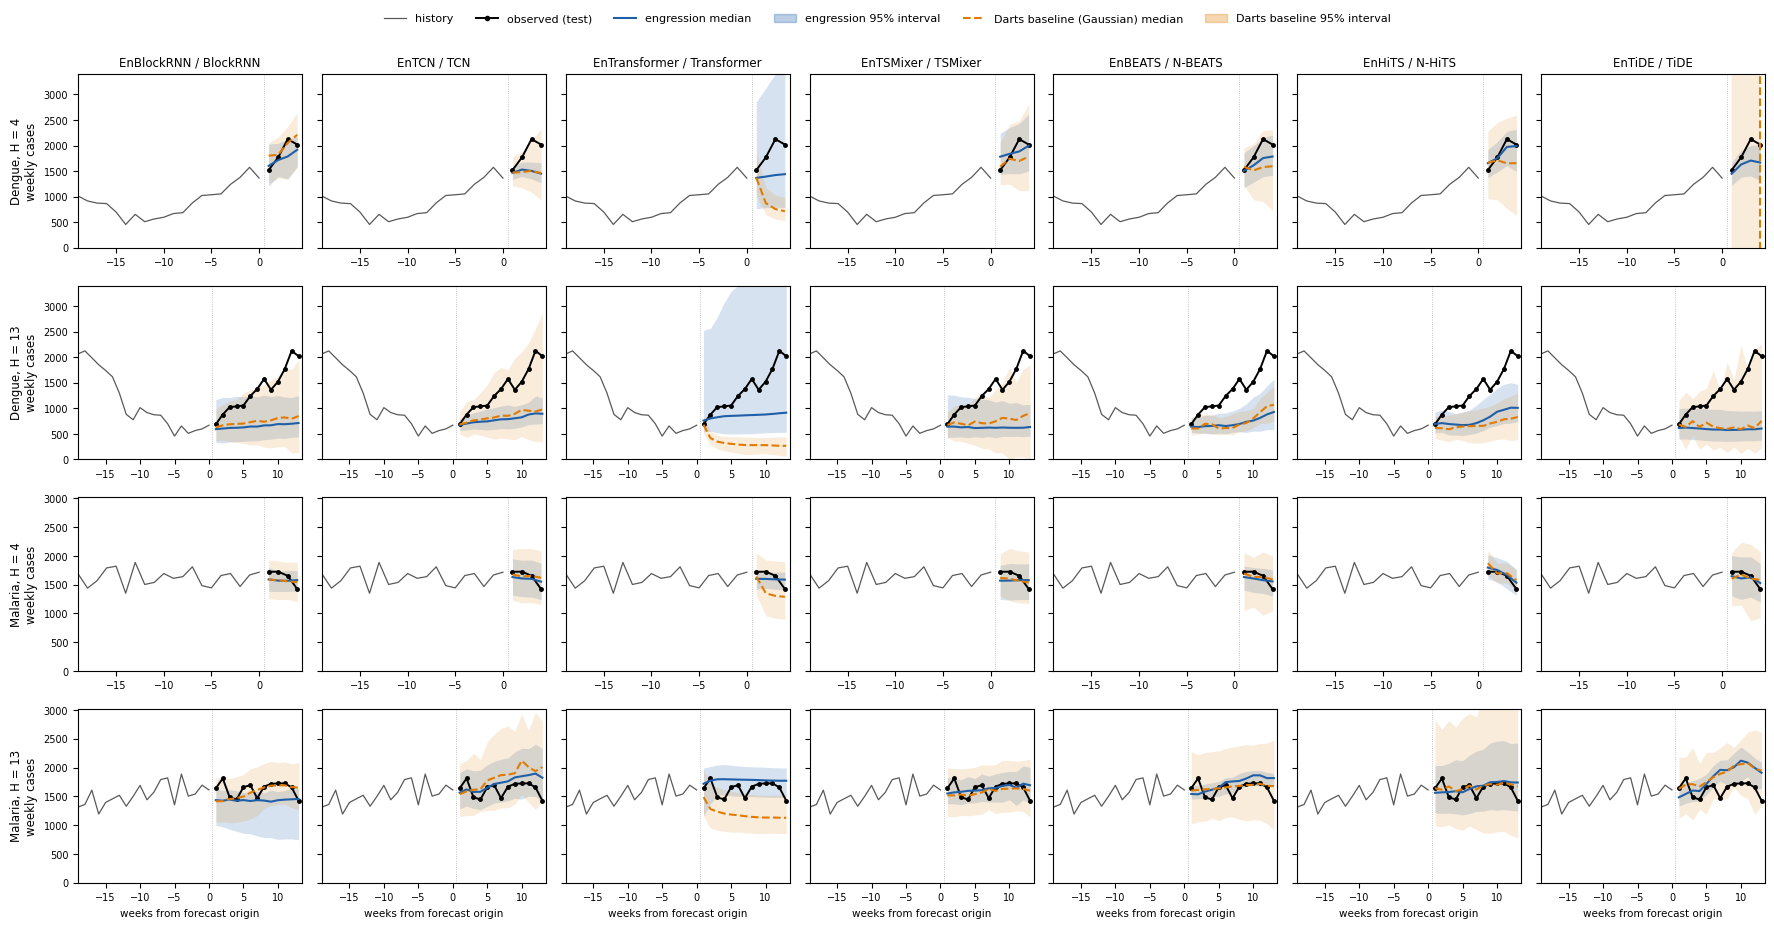

In [10]:
def pooled_samples(ds, key, h, kind):
    d = run_dir(ds, key, h, kind)
    files = sorted(glob.glob(os.path.join(d, "samples_seed*.npy")))
    if not files: return None
    a = np.concatenate([np.load(f) for f in files], axis=0)        # (seeds * R, H, S)
    return a.transpose(1, 0, 2).reshape(a.shape[1], -1)             # (H, all samples)

COL = {"engression": "#1f5fa8", "baseline": "#e07b00"}
present = [(ds, h) for ds in CFG["DATASETS"] for h in CFG["HORIZONS"]]
keys = list(MODELS)
fig, axes = plt.subplots(len(present), len(keys), figsize=(2.55 * len(keys), 2.3 * len(present)), sharey="row", squeeze=False)
QROWS = []
for r, (ds, h) in enumerate(present):
    sp = SPLITS[ds][h]; H = sp["H"]
    hist = sp["train_val"].values().ravel()[-CFG["PLOT_HISTORY"]:]
    xh = np.arange(-len(hist) + 1, 1); xt = np.arange(1, H + 1)
    ytop = CFG["PLOT_YMAX_FACTOR"] * max(hist.max(), sp["test"].values().max())
    for c, key in enumerate(keys):
        ax = axes[r, c]
        ax.plot(xh, hist, color="0.35", lw=0.9)
        ax.plot(xt, sp["test"].values().ravel(), color="black", lw=1.4, marker="o", ms=2.5)
        for kind in KINDS:
            s = pooled_samples(ds, key, h, kind)
            if s is None: continue
            lo, med, hi = (np.quantile(s, q, axis=1) for q in (CFG["ALPHA"] / 2, 0.5, 1 - CFG["ALPHA"] / 2))
            ax.fill_between(xt, lo, hi, color=COL[kind], alpha=0.18 if kind == "engression" else 0.14, lw=0)
            ax.plot(xt, med, color=COL[kind], lw=1.5, ls="-" if kind == "engression" else "--")
            QROWS += [dict(dataset=ds, horizon=h, model=key, kind=kind, step=i + 1, observed=float(sp["test"].values()[i, 0]),
                           q025=lo[i], median=med[i], q975=hi[i]) for i in range(H)]
        ax.axvline(0.5, color="0.7", lw=0.6, ls=":")
        ax.tick_params(labelsize=7); ax.set_xlim(xh[0], H + 0.5); ax.set_ylim(0, ytop)
        if r == 0: ax.set_title(f"{MODELS[key][0]} / {MODELS[key][1]}", fontsize=8.5)
        if c == 0: ax.set_ylabel(f"{ds.capitalize()}, H = {H}\nweekly cases", fontsize=8.5)
        if r == len(present) - 1: ax.set_xlabel("weeks from forecast origin", fontsize=7.5)
handles = [mlines.Line2D([], [], color="0.35", lw=0.9, label="history"),
           mlines.Line2D([], [], color="black", lw=1.4, marker="o", ms=3, label="observed (test)"),
           mlines.Line2D([], [], color=COL["engression"], lw=1.5, label="engression median"),
           mpatches.Patch(color=COL["engression"], alpha=0.3, label="engression 95% interval"),
           mlines.Line2D([], [], color=COL["baseline"], lw=1.5, ls="--", label="Darts baseline (Gaussian) median"),
           mpatches.Patch(color=COL["baseline"], alpha=0.3, label="Darts baseline 95% interval")]
fig.legend(handles=handles, loc="upper center", ncol=6, fontsize=8, frameon=False, bbox_to_anchor=(0.5, 1.01))
plt.tight_layout(rect=(0, 0, 1, 0.97))
for ext in ("png", "pdf"):
    plt.savefig(f"{CFG['OUT_DIR']}/fig1_forecasts.{ext}", dpi=200, bbox_inches="tight")
plt.show()
pd.DataFrame(QROWS).to_csv(f"{CFG['OUT_DIR']}/forecast_quantiles.csv", index=False)

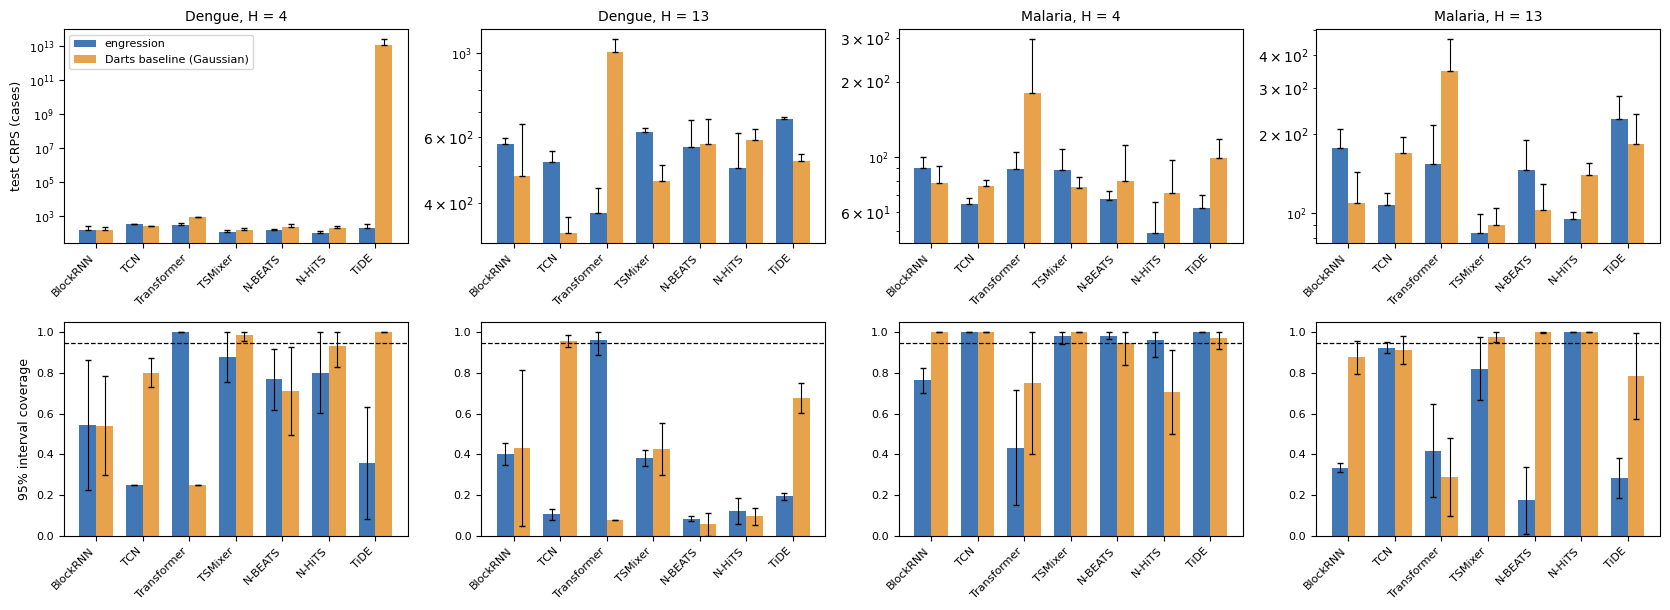

In [11]:
fig, axes = plt.subplots(2, len(present), figsize=(4.2 * len(present), 6.2), squeeze=False)
x = np.arange(len(keys)); w = 0.36
for c, (ds, h) in enumerate(present):
    for r, metric in enumerate(["CRPS", "Coverage95"]):
        ax = axes[r, c]
        for j, kind in enumerate(KINDS):
            vals, errs = [], []
            for key in keys:
                idx = (ds, h, key, kind, MODELS[key][0] if kind == "engression" else MODELS[key][1])
                vals.append(MEAN[metric].get(idx, np.nan)); errs.append(SD_SEEDS[metric].get(idx, np.nan))
            vals, errs = np.array(vals, float), np.nan_to_num(np.array(errs, float))
            lo = np.minimum(errs, vals - (0 if metric == "Coverage95" else vals * 0.999))   # keep bars inside the axis
            hi = np.minimum(errs, 1 - vals) if metric == "Coverage95" else errs
            ax.bar(x + (j - 0.5) * w, vals, w, yerr=np.vstack([np.clip(lo, 0, None), np.clip(hi, 0, None)]), color=COL[kind],
                   alpha=0.85 if kind == "engression" else 0.7, error_kw=dict(lw=0.8, capsize=2),
                   label="engression" if kind == "engression" else "Darts baseline (Gaussian)")
        if metric == "Coverage95":
            ax.axhline(1 - CFG["ALPHA"], color="black", ls="--", lw=0.9); ax.set_ylim(0, 1.05)
        else:
            ax.set_yscale("log")                     # a single exploding forecast must not flatten the rest
        ax.set_xticks(x); ax.set_xticklabels([MODELS[k][1] for k in keys], rotation=45, ha="right", fontsize=8)
        ax.tick_params(axis="y", labelsize=8)
        if r == 0: ax.set_title(f"{ds.capitalize()}, H = {SPLITS[ds][h]['H']}", fontsize=10)
        if c == 0: ax.set_ylabel("test CRPS (cases)" if metric == "CRPS" else "95% interval coverage", fontsize=9)
axes[0, 0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
for ext in ("png", "pdf"):
    plt.savefig(f"{CFG['OUT_DIR']}/fig2_crps_coverage.{ext}", dpi=200, bbox_inches="tight")
plt.show()

## Part 9 — Supplementary tables, fact sheet and saving

* **Table S1:** training time per fit and prediction time per ensemble of 100 trajectories (mean over seeds, seconds), with the accelerator used.
* **Table S2:** spread across training seeds (sd of the per-seed means) for CRPS, MAE and coverage.
* **Table S3:** the selected hyperparameters per dataset, model and horizon (also in `best_params.json`).
* **Fact sheet:** the facts the write-up needs, computed from the tables: the best model per setting, how often engression beats its own baseline, the coverage range, and the validation vs. test CRPS of each engression model. Everything is saved to `OUT_DIR`.

In [12]:
trows = []
for info in INFOS:
    t = pd.DataFrame(info["times"])
    trows.append(dict(dataset=info["dataset"], horizon=info["horizon"], Model=info["name"], kind=info["kind"],
                      accelerator=info.get("accelerator"), train_s_per_fit=t["train_seconds"].mean(),
                      predict_s_per_ensemble=t["predict_seconds_per_ensemble"].mean()))
TIMES = pd.DataFrame(trows).set_index(["dataset", "horizon", "Model"]).sort_index()
print("Table S1. Computational time (seconds, mean over seeds)"); display(TIMES.round(2))

S2 = SD_SEEDS[["CRPS", "MAE", "Coverage95"]].droplevel(["model", "kind"]).round(2)
print("Table S2. sd across training seeds"); display(S2)

prow = []
for (ds, key, h), params in sorted(BEST.items()):
    for k, v in params.items():
        prow.append(dict(dataset=ds, model=MODELS[key][0], horizon=h, parameter=k, value=v))
S3 = pd.DataFrame(prow).pivot_table(index=["model", "parameter"], columns=["dataset", "horizon"], values="value", aggfunc="first")
print("Table S3. Selected hyperparameters (engression models; the baselines reuse the architecture, lr and log transform)")
display(S3)

Table S1. Computational time (seconds, mean over seeds)


kind accelerator  train_s_per_fit  predict_s_per_ensemble
dataset horizon Model                                                                         
dengue  long    BlockRNN         baseline         gpu             8.94                    0.08
                EnBEATS        engression         gpu            17.46                    0.09
                EnBlockRNN     engression         gpu             9.21                    0.08
                EnHiTS         engression         gpu            10.58                    0.08
                EnTCN          engression         gpu             9.03                    0.08
                EnTSMixer      engression         gpu            19.36                    0.09
                EnTiDE         engression         gpu            12.20                    0.08
                EnTransformer  engression         gpu            31.41                    0.20
                N-BEATS          baseline         gpu            17.22                    0.09
                N-HiTS           baseline         gpu            10.28                    0.08
                TCN              baseline         gpu             8.81                    0.08
                TSMixer          baseline         gpu            19.04                    0.09
                TiDE             baseline         gpu            11.83                    0.08
                Transformer      baseline         gpu            30.74                    0.20
        short   BlockRNN         baseline         gpu            11.35                    0.09
                EnBEATS        engression         gpu            28.03                    0.10
                EnBlockRNN     engression         gpu            11.87                    0.09
                EnHiTS         engression         gpu            23.46                    0.09
                EnTCN          engression         gpu            11.33                    0.08
                EnTSMixer      engression         gpu            14.44                    0.08
                EnTiDE         engression         gpu            14.97                    0.09
                EnTransformer  engression         gpu            33.37                    0.12
                N-BEATS          baseline         gpu            27.78                    0.10
                N-HiTS           baseline         gpu            23.22                    0.10
                TCN              baseline         gpu            10.39                    0.08
                TSMixer          baseline         gpu            14.04                    0.08
                TiDE             baseline         gpu            14.59                    0.09
                Transformer      baseline         gpu            32.97                    0.12
malaria long    BlockRNN         baseline         gpu             8.91                    0.08
                EnBEATS        engression         gpu            29.39                    0.10
                EnBlockRNN     engression         gpu             9.33                    0.08
                EnHiTS         engression         gpu            35.10                    0.10
                EnTCN          engression         gpu            16.11                    0.08
                EnTSMixer      engression         gpu            16.72                    0.08
                EnTiDE         engression         gpu            13.22                    0.09
                EnTransformer  engression         gpu            34.83                    0.24
                N-BEATS          baseline         gpu            28.59                    0.10
                N-HiTS           baseline         gpu            35.23                    0.11
                TCN              baseline         gpu            14.99                    0.08
                TSMixer          baseline         gpu            16.81                    0.09
                TiDE             baseline      

Table S2. sd across training seeds


CRPS           MAE  Coverage95
dataset horizon Model                                                
dengue  long    N-BEATS        9.431000e+01  9.387000e+01        0.06
                EnBEATS        1.006500e+02  9.537000e+01        0.01
                BlockRNN       1.764800e+02  1.529900e+02        0.38
                EnBlockRNN     2.010000e+01  1.432000e+01        0.05
                N-HiTS         3.969000e+01  3.820000e+01        0.04
                EnHiTS         1.156500e+02  1.071400e+02        0.06
                TCN            3.436000e+01  3.802000e+01        0.03
                EnTCN          3.472000e+01  2.721000e+01        0.03
                TiDE           2.142000e+01  1.730000e+01        0.07
                EnTiDE         7.360000e+00  5.970000e+00        0.02
                Transformer    8.038000e+01  7.936000e+01        0.00
                EnTransformer  6.309000e+01  5.036000e+01        0.07
                TSMixer        4.867000e+01  5.009000e+01        0.13
                EnTSMixer      1.581000e+01  1.559000e+01        0.04
        short   N-BEATS        8.856000e+01  1.047700e+02        0.22
                EnBEATS        3.170000e+01  3.852000e+01        0.15
                BlockRNN       6.278000e+01  6.547000e+01        0.24
                EnBlockRNN     9.694000e+01  9.864000e+01        0.32
                N-HiTS         5.744000e+01  7.497000e+01        0.10
                EnHiTS         3.955000e+01  4.721000e+01        0.20
                TCN            1.724000e+01  1.898000e+01        0.07
                EnTCN          2.468000e+01  2.437000e+01        0.00
                TiDE           1.443379e+13  1.134416e+13        0.00
                EnTiDE         1.183600e+02  1.325800e+02        0.27
                Transformer    2.893000e+01  2.985000e+01        0.00
                EnTransformer  9.906000e+01  1.911500e+02        0.00
                TSMixer        4.537000e+01  7.337000e+01        0.03
                EnTSMixer      3.183000e+01  4.703000e+01        0.13
malaria long    N-BEATS        2.620000e+01  4.586000e+01        0.00
                EnBEATS        4.373000e+01  4.433000e+01        0.17
                BlockRNN       3.378000e+01  4.913000e+01        0.08
                EnBlockRNN     3.267000e+01  3.572000e+01        0.02
                N-HiTS         1.570000e+01  1.747000e+01        0.00
                EnHiTS         6.510000e+00  1.307000e+01        0.00
                TCN            2.499000e+01  3.552000e+01        0.07
                EnTCN          1.177000e+01  2.060000e+01        0.03
                TiDE           5.448000e+01  7.175000e+01        0.21
                EnTiDE         5.059000e+01  5.042000e+01        0.10
                Transformer    1.140400e+02  1.122400e+02        0.19
                EnTransformer  6.308000e+01  7.073000e+01        0.23
                TSMixer        1.470000e+01  2.546000e+01        0.03
                EnTSMixer      1.501000e+01  1.867000e+01        0.16
        short   N-BEATS        3.082000e+01  5.259000e+01        0.11
                EnBEATS        5.710000e+00  7.470000e+00        0.02
                BlockRNN       1.345000e+01  2.347000e+01        0.00
                EnBlockRNN     9.830000e+00  1.410000e+01        0.06
                N-HiTS         2.529000e+01  2.882000e+01        0.21
                EnHiTS         1.652000e+01  2.923000e+01        0.08
                TCN            4.680000e+00  4.850000e+00        0.00
                EnTCN          4.000000e+00  6.130000e+00        0.00
                TiDE           1.917000e+01  3.918000e+01        0.06
                EnTiDE         7.910000e+00  1.854000e+01        0.00
                Transformer    1.163800e+02  1.326200e+02        0.35
                EnTransformer  1.543000e+01  1.738000e+01        0.28
                TSMixer        7.690000e+00  2.178000e+01        0.00
                EnTSMixer      1.864000e+01  2.89

Table S3. Selected hyperparameters (engression models; the baselines reuse the architecture, lr and log transform)


dataset                                    dengue             malaria          
horizon                                      long     short      long     short
model         parameter                                                        
EnBEATS       dropout                         NaN       NaN  0.496837  0.003573
              expansion_coefficient_dim         9         4         6         3
              layer_widths                     40        54        31        86
              log_transform                  True     False     False     False
              lr                         0.001936   0.00005  0.000501  0.000056
...                                           ...       ...       ...       ...
EnTransformer nhead                             2         1         8         8
              noise_std                  1.616906  0.540981  1.426281  1.402274
              noise_type                 gaussian  gaussian   uniform   uniform
              num_decoder_layers                2         2         3         3
              num_encoder_layers                2         3         1         1

[64 rows x 4 columns]

In [13]:
# Fact sheet for the write-up (computed, not written by hand)
facts, vt = [], []
for ds in TABLES:
    for h in CFG["HORIZONS"]:
        try:
            m = MEAN.loc[(ds, h)]
        except KeyError:
            continue
        H = CFG["HORIZONS"][h]["H"]
        crps = m["CRPS"].droplevel(["model", "kind"])
        wins = [k for k in MODELS if (k, "engression") in m.index and (k, "baseline") in m.index
                and m.loc[(k, "engression"), "CRPS"].iloc[0] < m.loc[(k, "baseline"), "CRPS"].iloc[0]]
        pairs = [k for k in MODELS if (k, "engression") in m.index and (k, "baseline") in m.index]
        cov_e = m.xs("engression", level="kind")["Coverage95"]; cov_b = m.xs("baseline", level="kind")["Coverage95"]
        facts.append(dict(dataset=ds, H=H, best_by_CRPS=crps.idxmin(), best_CRPS=round(crps.min(), 1),
                          best_engression=crps[[MODELS[k][0] for k in MODELS if MODELS[k][0] in crps.index]].idxmin(),
                          best_baseline=crps[[MODELS[k][1] for k in MODELS if MODELS[k][1] in crps.index]].idxmin(),
                          engression_beats_own_baseline=f"{len(wins)} of {len(pairs)}",
                          engression_coverage_range=f"{cov_e.min():.2f}–{cov_e.max():.2f}",
                          baseline_coverage_range=f"{cov_b.min():.2f}–{cov_b.max():.2f}"))
        for key in MODELS:
            if (ds, key, h) in BEST and (key, "engression") in m.index:
                src = next(s for s in sources if s["dataset"] == ds and s["model"] == MODELS[key][0] and s["horizon"] == h)
                vt.append(dict(dataset=ds, H=H, Model=MODELS[key][0], val_CRPS=src["best_val_CRPS"],
                               test_CRPS=round(m.loc[(key, "engression"), "CRPS"].iloc[0], 1)))
FACTS = pd.DataFrame(facts); VT = pd.DataFrame(vt)
print("Fact sheet"); display(FACTS)
print("Validation (best trial, model fitted on train) vs. test (fitted on train + validation) CRPS of the engression models")
display(VT.set_index(["dataset", "H", "Model"]))

Fact sheet


,dataset,H,best_by_CRPS,best_CRPS,best_engression,best_baseline,engression_beats_own_baseline,engression_coverage_range,baseline_coverage_range
0,dengue,4,EnHiTS,99.6,EnHiTS,TSMixer,5 of 7,0.25–1.00,0.25–1.00
1,dengue,13,TCN,332.5,EnTransformer,TCN,3 of 7,0.08–0.96,0.06–0.96
2,malaria,4,EnHiTS,49.2,EnHiTS,N-HiTS,5 of 7,0.43–1.00,0.71–1.00
3,malaria,13,EnTSMixer,83.5,EnTSMixer,TSMixer,4 of 7,0.17–1.00,0.29–1.00


Validation (best trial, model fitted on train) vs. test (fitted on train + validation) CRPS of the engression models


val_CRPS  test_CRPS
dataset H  Model                             
dengue  4  EnBlockRNN        142.7      164.7
           EnTCN              79.7      329.4
           EnTransformer     137.3      300.7
           EnTSMixer         190.0      126.3
           EnBEATS           115.0      145.2
           EnHiTS            120.8       99.6
           EnTiDE            120.6      215.9
        13 EnBlockRNN        235.5      575.4
           EnTCN             250.3      515.0
           EnTransformer     270.4      376.2
           EnTSMixer         285.0      618.3
           EnBEATS           209.8      563.2
           EnHiTS            207.6      496.4
           EnTiDE            246.6      669.1
malaria 4  EnBlockRNN         80.2       89.9
           EnTCN              73.1       64.4
           EnTransformer      80.7       88.9
           EnTSMixer          72.8       88.4
           EnBEATS            71.3       67.2
           EnHiTS             71.1       49.2
           EnTiDE             71.2       61.9
        13 EnBlockRNN        206.3      176.7
           EnTCN             136.9      106.7
           EnTransformer     123.7      153.5
           EnTSMixer         132.7       83.5
           EnBEATS           194.5      145.7
           EnHiTS            130.5       94.4
           EnTiDE            167.5      228.5

In [14]:
out = CFG["OUT_DIR"]
ALL.to_csv(f"{out}/test_metrics_all_ensembles.csv", index=False)
MEAN.to_csv(f"{out}/test_metrics_mean.csv"); SD_SEEDS.to_csv(f"{out}/test_metrics_sd_seeds.csv")
TIMES.to_csv(f"{out}/tableS1_times.csv"); S2.to_csv(f"{out}/tableS2_sd_seeds.csv"); S3.to_csv(f"{out}/tableS3_hyperparameters.csv")
FACTS.to_csv(f"{out}/fact_sheet.csv", index=False); VT.to_csv(f"{out}/val_vs_test.csv", index=False)
split_table.to_csv(f"{out}/splits.csv"); pd.DataFrame(sources).to_csv(f"{out}/tuning_sources.csv", index=False)
json.dump({f"{ds}/{key}/{h}": dict(params=p, fingerprint=FPS[(ds, key, h)]) for (ds, key, h), p in BEST.items()},
          open(f"{out}/best_params.json", "w"), indent=2, default=str)
json.dump(dict(config=CFG, run_mode=RUN_MODE, run_models_this_session=RUN_MODELS, versions=VERSIONS, accelerator=ACCELERATOR,
               missing_tuning=missing, n_combinations=len(INFOS)), open(f"{out}/run_info.json", "w"), indent=2, default=str)
shutil.rmtree(os.path.join(out, "_staging"), ignore_errors=True)
expected = len(CFG["DATASETS"]) * len(MODELS) * len(CFG["HORIZONS"]) * len(KINDS)
print(f"{len(INFOS)} of {expected} combinations available."
      + ("" if len(INFOS) == expected else " Tables and figures are partial until the rest are trained."))
print(sorted(f for f in os.listdir(out) if not f.startswith("runs")))

56 of 56 combinations available.
['best_params.json', 'fact_sheet.csv', 'fig1_forecasts.pdf', 'fig1_forecasts.png', 'fig2_crps_coverage.pdf', 'fig2_crps_coverage.png', 'figS1_series.png', 'forecast_quantiles.csv', 'run_info.json', 'splits.csv', 'table1_dengue.csv', 'table1_dengue.tex', 'table2_malaria.csv', 'table2_malaria.tex', 'tableS1_times.csv', 'tableS2_sd_seeds.csv', 'tableS3_hyperparameters.csv', 'test_metrics_all_ensembles.csv', 'test_metrics_mean.csv', 'test_metrics_sd_seeds.csv', 'tuning_sources.csv', 'val_vs_test.csv']
